# Pendahuluan

Terdapat banyak aplikasi platform streaming legal dan illegal untuk menonton film, series, anime, maupun drama. Di kesempatan kali saya akan mencoba mengscrapping aplikasi yang sering dipakai untuk streaming film pada Google Play. Kenapa Google Play? Pertama, pengunaan android yang lebih banyak daripada IOS. Kedua terdapat library untuk mengscrapping Google Play bernama google-play-scraper.Library ini berfungsi untuk mengscrap otomatis dari situs google play dan mengembalikan hasilnya kedalam bentuk dictionary

Kita tentukan terlebih dahulu aplikasi apa yang sering dipakai oleh orang lain dilihat dari jumlah download atau pengguna. Berikut adalah 3 aplikasi yang sering digunakan sebagai streaming platform

1. Netflix (1M+ Download)
2. Prime Video (500jt+ Download)
3. Crunchyroll (100jt+ Download)

![Crunchyroll](./gambar/Crunchyroll.png)
![Netflix](./gambar/Netflix.png)
![Prime Video](./gambar/Prime_video.png)

# 1. Scrapping 

In [9]:
from google_play_scraper import Sort, reviews
import pandas as pd
import time

#Link per aplikasi. Aplikasi : Link
APK = {
    "Netflix": "com.netflix.mediaclient",
    "Prime Video": "com.amazon.avod.thirdpartyclient",
    "Crunchyroll": "com.crunchyroll.crunchyroid",
}

#Kolom yang bakal di analisa
COLUMNS = ["reviewId", "userName", "content", "score", "thumbsUpCount", "at", "appVersion", "app", "language"]
# list bahasa
LANG = ["id", "en"]


ALL_RESULT = []

for i, link in APK.items():
    for j in LANG:
        result, continuation_token = reviews(
            link, #link aplikasi google play
            lang=j, #bahasa
            sort=Sort.NEWEST, #urutkan dari terbaru
            country='id', #negara ini penting jika tidak, outpunya tidak ada
            count = 500, #jumlah data yang ingin di scrap
            continuation_token = None #melanjutkan review yang baru
        )
        for review in result:
            review["app"] = i
            review["language"] = j
            ALL_RESULT.append(review)

        time.sleep(0.5)#kasih jeda untuk tidak overload server

#mengubah ke dataframe dan upload jadi csv
df = pd.DataFrame(ALL_RESULT)
df = df[[c for c in COLUMNS if c in df.columns]].copy()
df.to_csv("data.csv", index=False, encoding="utf-8-sig")

In [10]:
print(df)

                                  reviewId         userName  \
0     8836ef24-77d2-4310-8362-1d5e436ce66d   Akhsan Arrafff   
1     546def20-acd0-4c83-af68-314b93755fca   Celine Carissa   
2     9b991fd9-ebe9-407d-ac20-997f1d346985       SYAIFULLAH   
3     10b8bdce-2b41-46ab-838c-9e50826c8808           hdrswn   
4     9b4e0564-18e1-42b1-86d8-e8521ee6d024      Nay Nindyta   
...                                    ...              ...   
2995  bb922bcd-a548-4263-917d-8eef7e762153    Tritesh Hulke   
2996  41f04e3a-9d1f-4f31-98ed-913d3f01dc2b      R.S Axaline   
2997  1ea3e91b-2408-4c77-8260-d2f140a26054        Asha Rani   
2998  ce81a1af-dc8a-48e2-86d0-6e17c11862b9  Mangesh Chikane   
2999  43a5a84a-80a3-4531-844a-b3f3d086c111   Depprsed young   

                                                content  score  thumbsUpCount  \
0                                                 👍👍👍👍👍      5              0   
1     penjahat nya nambah2 trus kapan kelarnya nih b...      5              0   


# 2. Exploratory Data Analysis

Setelah mendapatkan data mentahnya langkah selanjutnya adalah melihat data mentah tersebut dengan melihat distribusi, bentuk data, dan sebagainya agar kita dapat menentukan langkah atau strategi saat mengolah data

In [11]:
df = pd.read_csv("data.csv")

#labeling score 
df = df.dropna(subset=["content"]).copy()
df["label"] = df["score"].map({1: "negative", 2: "negative", 3: "neutral",
                               4: "positive", 5: "positive"})
print(df.shape)

(3000, 10)


### 2.1. Missing or Duplicate Value

In [12]:
duplicate = df.duplicated().sum()
nan = round(df.isna().sum()/len(df)*100).astype(str) + '%'

print(duplicate)
print(nan)

0
reviewId          0.0%
userName          0.0%
content           0.0%
score             0.0%
thumbsUpCount     0.0%
at                0.0%
appVersion       23.0%
app               0.0%
language          0.0%
label             0.0%
dtype: object


Terdapat Missing value pada kolom appVersion. Kolom appVersion bisa di drop

### 2.2. Distribution Label & Visualization

label
negative    1303
neutral      217
positive    1480
dtype: int64


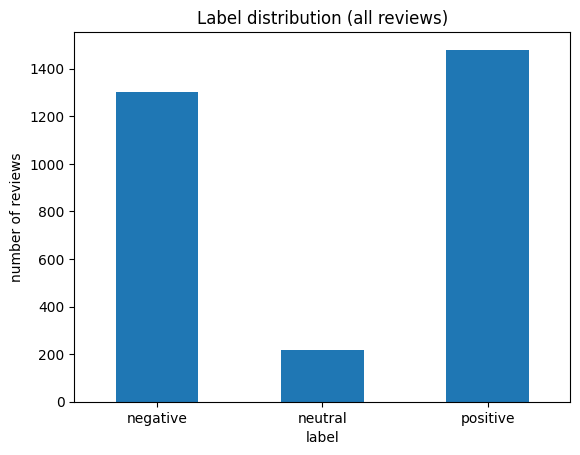

In [13]:
import matplotlib.pyplot as plt
all_label = pd.crosstab(df["label"], df["language"]).sum(axis=1)
print(all_label)
ax = all_label.plot.bar(rot=0)
ax.set_title("Label distribution (all reviews)")
ax.set_xlabel("label")
ax.set_ylabel("number of reviews")
plt.show()

Pada distribusi tersebut bisa dilihat negative dan positive hampir sama kecuali netral sehingga terjadi imbalance. Untuk netral kita bisa pertahankan atau drop tergantung tujuan akhir kita. Di kasus saya, saya memilih drop karena komentar netral itu terkadang tidak bisa diandalkan(unreliable) dan terkadang reviewnya yang mixed campur aduk dengan positive review . Sehingga trade-off nya adalah jika kita drop model tidak bisa mempelajari mixed review. Tetapi menurut saya positive dan negative review sudah cukup untuk menentukan aplikasi mana yang harus di download.

language   en   id
label             
negative  553  750
neutral   105  112
positive  842  638


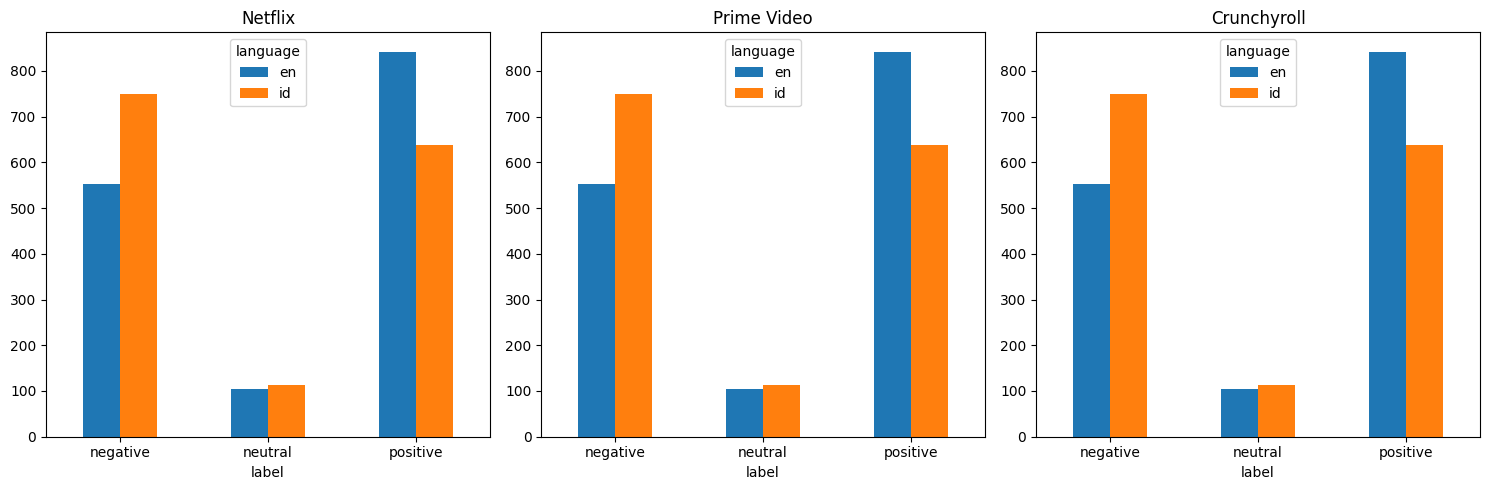

In [14]:
#Plot melihat label per aplikasi

label_counts = pd.crosstab(df["label"], df["language"])
print(label_counts)

apps = df["app"].unique()
fig, axes = plt.subplots(1, len(apps), figsize=(15, 5))

for ax, app in zip(axes, apps):
    sub = df[df["app"]==app]
    label_counts.plot.bar(ax=ax, rot=0)
    ax.set_title(app) 

plt.tight_layout()
plt.show()


Ternyata data negative review kebanyakan berasal dari negative command bahasa indonesia. Ini menjadi pertimbangan untuk menentukan fitur di trainingnya karena jika tidak model akan mengira jika reviewnya adalah bahasa indonesia maka review tersebut negativeg

### 2.3. Review Length per rating


"median words, by star",1,2,3,4,5
language,,,,,
en,19.0,16.5,16.0,9.0,3.0
id,11.0,17.0,15.5,12.0,3.0


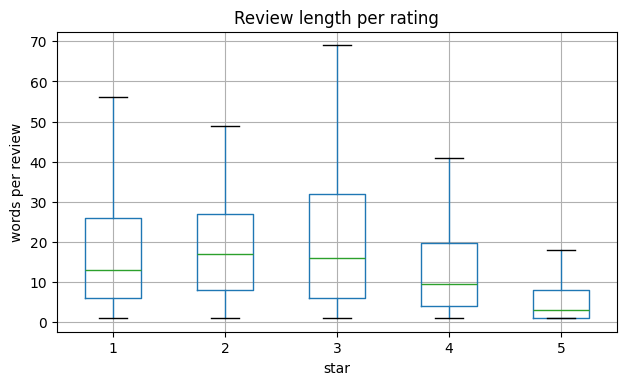

In [15]:
df["n_words"] = df["content"].str.split().str.len()
display(df.groupby(["language", "score"])["n_words"].median().unstack().rename_axis(columns="median words, by star"))

df.boxplot(column="n_words", by="score", showfliers=False, figsize=(7, 4))
plt.title("Review length per rating")
plt.suptitle("")
plt.xlabel("star")
plt.ylabel("words per review")
plt.show()

Terkadang komentar positive terdapat orang iseng yang cuman komen emoji, kata random dibawah 5 kata dan tidak memiliki alasan mengapa aplikasi tersebut bagus. Filter kata-kata yang tidak lebih dari 5 kata

### 2.4. Dominant Words per rating

In [16]:
from nltk.corpus import stopwords, wordnet
import regex as re
from collections import Counter

NEGATIONS = {"id": {"tidak", "bukan", "belum", "jangan", "kurang", "tanpa"},
             "en": {"not", "no", "nor", "never", "don't", "don", "t"}}
STOP = {"id": set(stopwords.words("indonesian")) - NEGATIONS["id"],
        "en": set(stopwords.words("english")) - NEGATIONS["en"]}
APP_NAMES = {"netflix", "prime", "amazon", "crunchyroll", "crunchy"}

def simple_tokens(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"can['’]t", "cannot", text)
    text = re.sub(r"won['’]t", "will not", text)
    text = re.sub(r"n['’]t\b", " not", text)
    return re.findall(r"[a-z]+", text)

# Domain words: frequent in EVERY rating, so they don't describe any rating
DOMAIN_STOP = {"aplikasi", "apk", "app", "apps", "application", "nya", "nonton", "film", "watch",
               "watching", "movies", "movie", "video", "anime", "the", "shows"}

def eda_tokens(text, lang, remove_domain=False):
    return [w for w in simple_tokens(text)
            if w not in STOP[lang] and w not in APP_NAMES and (len(w) > 2 or w == "no")
            and not (remove_domain and w in DOMAIN_STOP)]

def top_words_per_rating(column, n=10):
    for lang in LANG:
        table = {}
        for star in range(1, 6):
            counts = Counter(w for toks in df[(df["language"] == lang) & (df["score"] == star)][column] for w in toks)
            table[f"{star}★"] = [f"{w} ({c})" for w, c in counts.most_common(n)]
        print(f"Top {n} words per rating - {lang}")
        display(pd.DataFrame(table))

df["eda_tokens"] = [eda_tokens(t, l) for t, l in zip(df["content"], df["language"])]
df["eda_tokens_nodomain"] = [eda_tokens(t, l, remove_domain=True) for t, l in zip(df["content"], df["language"])]

top_words_per_rating("eda_tokens")

Top 10 words per rating - id


,1★,2★,3★,4★,5★
0,aplikasi (153),nya (47),nya (38),film (28),bagus (134)
1,gak (123),subtitle (25),nonton (34),nya (24),film (80)
2,nonton (122),tidak (23),tidak (28),bagus (22),nya (57)
3,nya (116),nonton (21),anime (22),tolong (18),nonton (37)
4,tidak (113),indonesia (18),tolong (22),the (15),mantap (37)
5,aja (105),tolong (18),film (17),subtitle (15),good (36)
6,udah (100),film (17),subtitle (17),anime (15),keren (31)
7,login (93),langganan (17),indonesia (17),tidak (13),banget (31)
8,bayar (74),gak (17),bagus (16),nonton (12),aplikasi (29)
9,langganan (73),udah (16),video (15),aplikasi (12),the (29)


Top 10 words per rating - en


,1★,2★,3★,4★,5★
0,not (240),not (41),not (60),good (39),good (169)
1,app (195),ads (17),app (39),app (36),app (124)
2,watch (115),app (15),good (21),not (34),love (89)
3,subscription (89),no (15),anime (21),movies (18),best (78)
4,ads (89),even (13),watch (18),anime (18),great (77)
5,even (85),streaming (13),no (17),like (15),movies (61)
6,no (71),subscription (12),movies (16),watch (14),nice (48)
7,pay (56),get (12),like (15),shows (11),anime (47)
8,cannot (55),english (10),watching (15),hindi (11),watch (47)
9,still (54),like (9),pay (13),great (11),not (34)


Pada review bintang 1 kata yang mendominasi adalah aplikasi dan ada juga apps pada bahasa inggris. Ini menunjukkan bahwa pada bintang 1 banyak orang menggunakan kata-kata "aplikasi" atau "apps" namun tidak ada kaitannya sehingga kita harus membuang kata tersebut dengan stopword

Top 10 words per rating - id


,1★,2★,3★,4★,5★
0,gak (123),subtitle (25),tidak (28),bagus (22),bagus (134)
1,tidak (113),tidak (23),tolong (22),tolong (18),mantap (37)
2,aja (105),indonesia (18),subtitle (17),subtitle (15),good (36)
3,udah (100),tolong (18),indonesia (17),tidak (13),keren (31)
4,login (93),langganan (17),bagus (16),daftar (11),banget (31)
5,bayar (74),gak (17),gak (13),series (10),tidak (28)
6,langganan (73),udah (16),udah (12),udah (10),suka (24)
7,premium (65),episode (13),indo (12),bahasa (10),tolong (21)
8,akun (55),sih (11),banget (12),indonesia (10),and (18)
9,masuk (55),premium (11),premium (12),gak (9),terbaik (16)


Top 10 words per rating - en


,1★,2★,3★,4★,5★
0,not (240),not (41),not (60),good (39),good (169)
1,subscription (89),ads (17),good (21),not (34),love (89)
2,ads (89),no (15),no (17),like (15),best (78)
3,even (85),even (13),like (15),hindi (11),great (77)
4,no (71),streaming (13),pay (13),great (11),nice (48)
5,pay (56),subscription (12),please (12),available (10),not (34)
6,cannot (55),get (12),episode (12),nice (9),like (34)
7,still (54),english (10),available (11),please (8),one (27)
8,one (45),like (9),many (10),make (8),series (26)
9,free (41),please (9),free (10),add (8),streaming (26)


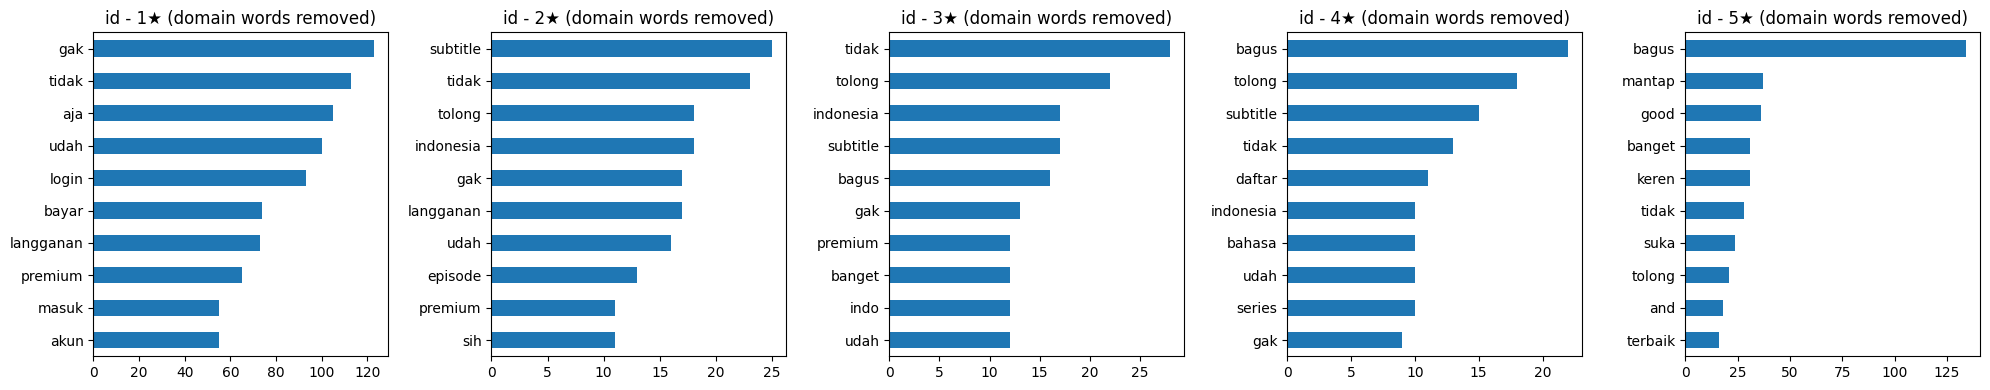

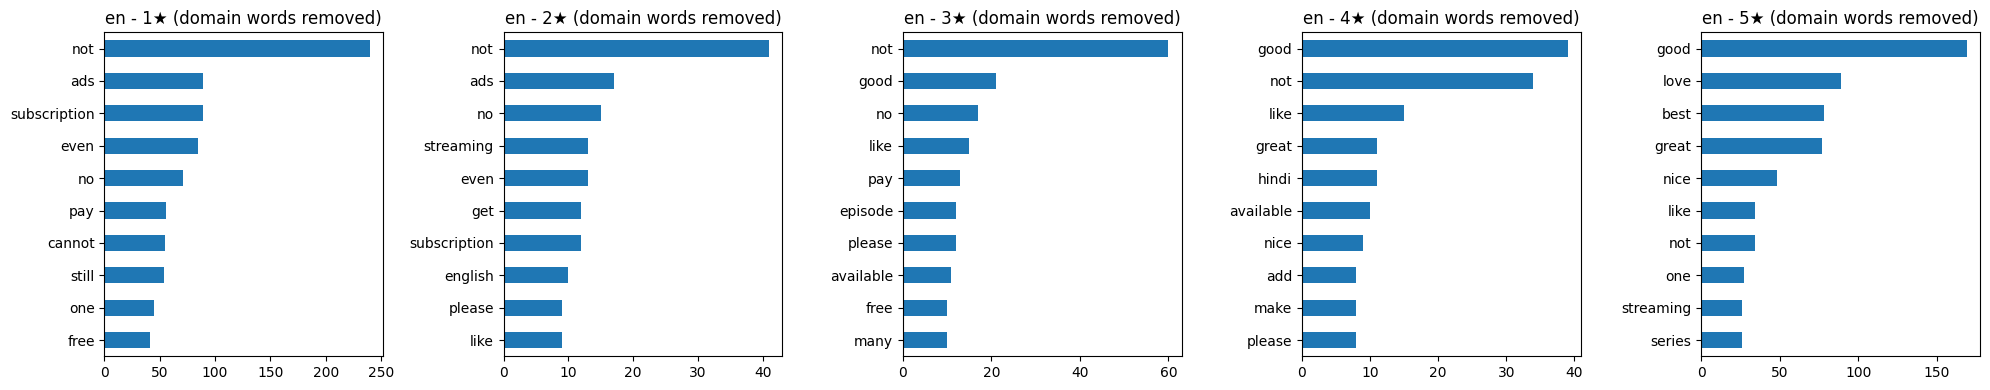

In [17]:
top_words_per_rating("eda_tokens_nodomain")

for lang in LANG:
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, star in zip(axes, range(1, 6)):
        counts = Counter(w for toks in df[(df["language"] == lang) & (df["score"] == star)]["eda_tokens_nodomain"] for w in toks)
        pd.Series(dict(counts.most_common(10))).sort_values().plot.barh(ax=ax)
        ax.set_title(f"{lang} - {star}★ (domain words removed)")
    plt.tight_layout()
    plt.show()

### 2.4 Non-Standard Words

In [18]:
import numpy as np
{
    "id": {
        "gak": "tidak", "ga": "tidak", "gk": "tidak", "g": "tidak", "nggak": "tidak", "ngga": "tidak",
        "enggak": "tidak", "engga": "tidak", "kagak": "tidak", "tdk": "tidak", "gaa": "tidak",
        "gabisa": "tidak bisa", "gbs": "tidak bisa", "blm": "belum", "udh": "sudah", "udah": "sudah",
        "sdh": "sudah", "dah": "sudah", "uda": "sudah", "yg": "yang", "dgn": "dengan", "krn": "karena",
        "karna": "karena", "tp": "tapi", "tpi": "tapi", "jd": "jadi", "jdi": "jadi", "sy": "saya",
        "aku": "saya", "gw": "saya", "gue": "saya", "gua": "saya", "km": "kamu", "bgt": "banget",
        "bngt": "banget", "aja": "saja", "aj": "saja", "kalo": "kalau", "klo": "kalau", "gmn": "bagaimana",
        "gimana": "bagaimana", "knp": "kenapa", "knpa": "kenapa", "trs": "terus", "trus": "terus",
        "lg": "lagi", "lgi": "lagi", "sm": "sama", "bs": "bisa", "dr": "dari", "utk": "untuk",
        "org": "orang", "sampe": "sampai", "skrg": "sekarang", "tlg": "tolong", "makasih": "terima kasih",
        "mksh": "terima kasih", "thx": "terima kasih", "mantul": "mantap", "mantab": "mantap",
        "apk": "aplikasi", "app": "aplikasi", "apl": "aplikasi", "lemot": "lambat", "lelet": "lambat",
        "ngelag": "lambat", "ribet": "rumit", "bener": "benar", "emg": "memang", "emang": "memang",
        "byk": "banyak", "bnyk": "banyak", "msh": "masih", "pdhl": "padahal", "hrs": "harus",
        "jgn": "jangan", "pake": "pakai", "dpt": "dapat", "dapet": "dapat", "ilang": "hilang",
        "tau": "tahu", "nonton": "menonton", "ntn": "menonton", "pilem": "film", "subtitel": "subtitle",
        "eps": "episode", "ep": "episode", "eror": "error", "tetep": "tetap", "mulu": "melulu",
        "baguss": "bagus", "kerenn": "keren", "bgus": "bagus", "kek": "seperti", "kayak": "seperti",
    },
    "en": {
        "dont": "do not", "doesnt": "does not", "didnt": "did not", "cant": "cannot", "wont": "will not",
        "isnt": "is not", "arent": "are not", "wasnt": "was not", "havent": "have not", "im": "i am",
        "ive": "i have", "youre": "you are", "thats": "that is", "u": "you", "ur": "your", "r": "are",
        "pls": "please", "plz": "please", "thx": "thanks", "ty": "thank you", "bc": "because",
        "cuz": "because", "coz": "because", "gonna": "going to", "wanna": "want to", "idk": "i do not know",
        "ppl": "people", "acc": "account", "vid": "video", "vids": "videos", "subs": "subtitles",
        "ep": "episode", "eps": "episodes", "ok": "okay", "luv": "love", "awsome": "awesome",
        "lol": "", "omg": "",
    },
}

rows = []
for lang in LANG:
    tokens = [w for t in df[df["language"] == lang]["content"] for w in simple_tokens(t)]
    slang_hits = [w for w in tokens if w in SLANG[lang]]
    rows.append({"language": lang, "tokens": len(tokens), "slang tokens": len(slang_hits),
                 "% slang": round(100 * len(slang_hits) / len(tokens), 2),
                 "reviews with slang (%)": round(100 * df[df["language"] == lang]["content"].apply(
                     lambda t: any(w in SLANG[lang] for w in simple_tokens(t))).mean(), 1)})
    print(f"Top 15 slang words ({lang}):", Counter(slang_hits).most_common(15))
display(pd.DataFrame(rows))

# Slang share per rating
df["slang_share"] = [np.mean([w in SLANG[l] for w in simple_tokens(t)]) if simple_tokens(t) else 0
                     for t, l in zip(df["content"], df["language"])]
display((df.groupby(["language", "score"])["slang_share"].mean().unstack() * 100).round(2)
          .rename_axis(columns="% slang tokens, by star"))



NameError: name 'SLANG' is not defined

Pada bahasa indonesia terdapat banyak slang word, typo, dan kata serapan sehingga kita harus melakukan sesuatu pada kata-kata tersebut

In [ ]:
en_tokens = [w for toks in df[df["language"] == "en"]["eda_tokens"] for w in toks]
not_in_wordnet = Counter(w for w in en_tokens if not wordnet.synsets(w))
print("English reviews - most frequent words NOT in WordNet:")
display(pd.DataFrame(not_in_wordnet.most_common(25), columns=["word", "count"]).T)

English reviews - most frequent words NOT in WordNet:


,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
word,app,cannot,without,everything,anything,something,would,apps,hai,could,...,offline,pls,since,uninstalled,que,else,others,everyone,bhi,wanna
count,418,93,27,27,25,25,24,22,22,19,...,12,11,10,10,10,8,8,8,8,7


Pada bahasa inggris kita harus juga mengatasi kata yang sering keluar tapi tidak ada di wordnet 

In [ ]:
def distinctive_per_rating(lang, star, n=10, min_count=5, column="eda_tokens", frame=None):
    frame = df if frame is None else frame
    sub = frame[frame["language"] == lang]
    inside = Counter(w for toks in sub[sub["score"] == star][column] for w in toks)
    outside = Counter(w for toks in sub[sub["score"] != star][column] for w in toks)
    total_in, total_out = sum(inside.values()), sum(outside.values())
    scores = {w: np.log(((inside[w] + 1) / total_in) / ((outside[w] + 1) / total_out))
              for w in inside if inside[w] >= min_count}
    return pd.Series(scores, dtype=float).sort_values(ascending=False).head(n)

for lang in LANG:
    table = {f"{s}★": distinctive_per_rating(lang, s).index.tolist() for s in range(1, 6)}
    print(f"Most distinctive words per rating - {lang}")
    display(pd.DataFrame.from_dict(table, orient="index").T)

Most distinctive words per rating - id


,1★,2★,3★,4★,5★
0,mending,yah,translate,tambahin,baguss
1,tolol,dubbing,drama,tambahkan,keren
2,log,indonesianya,kurang,series,good
3,kocak,kecewa,kasih,daftar,very
4,berhenti,kadang,hitam,kayak,puas
5,sumpah,gambar,suara,app,nice
6,habis,filmnya,kadang,bahasa,mantap
7,gajelas,update,gua,the,best
8,skip,subtitle,indo,and,terbaik
9,busuk,screen,jangan,salah,hiburan


Most distinctive words per rating - en


,1★,2★,3★,4★,5★
0,worse,pin,list,feature,fantastic
1,completely,profile,picture,dubbed,excellent
2,password,que,big,dub,best
3,subscribe,support,skip,available,smooth
4,disappointing,already,annoying,hindi,awesome
5,useless,english,something,season,love
6,scam,getting,available,stars,great
7,company,showing,lot,amazing,nice
8,worst,streaming,option,make,thank
9,forced,get,episodes,better,family


### 2.5 Other Language

In [ ]:
from langdetect import detect, LangDetectException
def detect_lang(text):
    try:
        return detect(text.lower())
    except LangDetectException:
        return "unknown"


df["other_lang"] = ~df["detected"].isin(LANG)      # not id and not en

length_group = pd.cut(df["n_words"], [0, 3, 10, 10_000], labels=["1-3 words", "4-10 words", ">10 words"])
display((df.groupby(length_group, observed=True)["other_lang"].mean() * 100).round(1)
          .rename("% detected as other language"))

other = df[df["other_lang"] & (df["n_words"] > 10)]
print("Long reviews detected as another language:", len(other))
display(other.sample(min(10, len(other)), random_state=3)[["app", "language", "detected", "content"]])

n_words
1-3 words     71.8
4-10 words    18.2
>10 words      3.8
Name: % detected as other language, dtype: float64

Long reviews detected as another language: 49


,app,language,detected,content
886,Netflix,en,tl,nag auto deduct kahit di na gingamit. tapos ng...
2444,Crunchyroll,id,tl,"apk dongo, pake apk ini aja ngga tiba² saldo g..."
591,Netflix,en,it,salta parti di film senza fartelo capire e anc...
2852,Crunchyroll,en,hr,Jo Anime purane hai usko to Hindi dubbed le ao 👎🏻
1796,Prime Video,en,pt,Minha experiência com o aplicativo foi péssima...
1693,Prime Video,en,es,Una experiencia cada vez más frustrante. Demas...
1015,Prime Video,id,tl,"gimana si gabisa login, login pakai password g..."
2853,Crunchyroll,en,pt,"episódios travados em ""continuar assistindo"" s..."
2770,Crunchyroll,en,es,En pocas palabras la aplicacion esta bien perr...
443,Netflix,id,de,SARAN KU SI TIAP BULAN TERTENTU DI ADAKAN HARG...


Terdapat bahasa lain selain yang kita mau yaitu bahasa indonesia, dan inggris saat menggunakan library langdetect. Buang seberapa yang terdeteksi bahasa lain

### 2.6 Short Review VS Review with reasons

In [ ]:
REASON_MIN_WORDS = 5

df["has_reason"] = df["n_words"] >= REASON_MIN_WORDS
share = pd.crosstab([df["language"]], df["score"], values=~df["has_reason"], aggfunc="mean") * 100
print(f"% of reviews with fewer than {REASON_MIN_WORDS} words, per rating:")
display(share.round(1))

print("Examples of short reviews:")
display(df[~df["has_reason"]].sample(10, random_state=2)[["app", "language", "score", "content"]])

long_df = df[df["has_reason"]]                  
for lang in LANG:
    table = {f"{star}★": distinctive_per_rating(lang, star, column="eda_tokens_nodomain", frame=long_df).index.tolist()
             for star in range(1, 6)}
    print(f"Distinctive words per rating, reviews with >= {REASON_MIN_WORDS} words - {lang}")
    display(pd.DataFrame.from_dict(table, orient="index").T)

% of reviews with fewer than 5 words, per rating:


score,1,2,3,4,5
language,,,,,
en,17.0,16.9,20.4,35.5,58.3
id,20.0,7.9,16.1,18.9,64.3


Examples of short reviews:


,app,language,score,content
767,Netflix,en,5,osm
2319,Crunchyroll,id,4,bagus
1451,Prime Video,id,5,mantap
2495,Crunchyroll,id,1,anime gak lengkap
561,Netflix,en,1,movies dont play
2390,Crunchyroll,id,1,pendo dg depe admin
913,Netflix,en,5,good at quality
1163,Prime Video,id,5,bagus
642,Netflix,en,5,perfect
819,Netflix,en,5,good


Distinctive words per rating, reviews with >= 5 words - id


,1★,2★,3★,4★,5★
0,mending,yah,translate,tambahin,keren
1,tolol,dubbing,drama,tambahkan,its
2,kocak,indonesianya,kasih,series,baguss
3,berhenti,kadang,hitam,daftar,original
4,log,kecewa,suara,kayak,terbaik
5,sumpah,filmnya,gua,bahasa,best
6,habis,update,jangan,and,pokoknya
7,skip,gambar,indo,salah,perbanyak
8,potong,screen,layar,lengkap,platform
9,email,subtitle,ulang,menonton,streaming


Distinctive words per rating, reviews with >= 5 words - en


,1★,2★,3★,4★,5★
0,worse,pin,list,feature,fantastic
1,completely,profile,picture,amazing,smooth
2,password,que,big,dubbed,best
3,subscribe,support,skip,available,awesome
4,disappointing,english,annoying,hindi,thank
5,useless,already,something,dub,great
6,company,getting,available,stars,family
7,locked,showing,option,make,excellent
8,scam,streaming,episodes,season,library
9,forced,get,episode,better,love


Karena banyaknya komen positif yang pendek dan tidak ada alasannya kita coba buang dan hasilnya distinctive wordnya berubah sehingga komen tersebut ada alasan kenapa ia suka dengan aplikasinya.

Berikut adalah ringkasan EDA yang kita lalui

| Penemuan | Langkah/Rencana |
|---|---|
| 1. Missing & Duplicate Value | Drop |
| 2. Negative review kebanyakan berasal dari bahasa indonesia | Pertimbangkan fitur yang dapat mudah membuat model menandai review bahasa indonesia = review negatif | 
| 3. Non-standart words seperti slang, typo, dan serapan | ubah ke kata yang lebih baku atau diperbaiki jika typo |  
| 4. Bahasa reviewnya tidak berasal dari inggris atau bahasa indonesia | Gunakan library langdetect dan buang |
| 5. Kebanyakan positive review hanya berisi emoji, kata random, atau hanya 1 kata tanpa alasan | Buang yang kalimatnya pendek dari 2 kata" | 

# 3. Preprocessing

| Step | What it does |
|---|---|
| 1. Language filter | Memfilter review yang lebih pendek dari 5 kata, bukan bahasa indonesia atau inggris |
| 2. Emoji to text | mengubah 👍 → *thumbs_up* sehingga emoji masih berperan untuk sentiment analysis|
| 2b. Case folding | lowercase |
| 3. Cleaning | membuang semua mention, url, emoji, data NaN|
| 4. Tokenizing | membelah kalimat menjadi per kata |
| 5. App-name removal | mengatasi model untuk menganggap review indonesia = review negatif |
| 6. Normalization | mengatasi typo dan slang serta serapan |
| 7. Stopword removal | stopword dan negasi serta domain stop untuk mengatasi kata yang sering di gunakan namun tidak ada arti |
| 8. Lemmatization (English) | lematasi wordnet contoh *movies → movie*, *was → be* |

In [ ]:
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer, PorterStemmer
import emoji

FILTER_OTHER_LANG = True
KEEP_DETECTED = {"id": {"id", "en", "ms", "tl"}, "en": {"id", "en", "ms", "tl"}} 

lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

def case_fold(text):
    return text.lower()

def emoji_to_text(text):
    return emoji.demojize(text, delimiters=(" ", " "))

def clean(text):
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[@#]\w+", " ", text)
    text = re.sub(r"can['’]t", "cannot", text)
    text = re.sub(r"won['’]t", "will not", text)
    text = re.sub(r"n['’]t\b", " not", text)
    text = re.sub(r"['’`]", "", text)
    text = re.sub(r"[^a-z_\s]", " ", text)        # "_" kept for emoji words (thumbs_up)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    return text

def normalize(tokens, lang):
    out = []
    for w in tokens:
        short = re.sub(r"(.)\1+", r"\1", w)          # bgtt -> bgt, for dictionary lookup only
        if w in SLANG[lang]:
            out.append(SLANG[lang][w])
        elif short in SLANG[lang]:
            out.append(SLANG[lang][short])
        else:
            out.append(w)
    return " ".join(out).split()

def remove_stopwords(tokens, lang):
    return [w for w in tokens if w not in STOP[lang]]

def lemmatize(tokens, lang):
    if lang != "en" or not tokens:
        return tokens
    return [lemmatizer.lemmatize(w, wordnet_pos(tag)) for w, tag in pos_tag(tokens)]

def preprocess_steps(text, lang):
    s = {"0 raw": text}
    s["0b emoji to text"] = emoji_to_text(text)
    s["1 case folding"] = case_fold(s["0b emoji to text"])
    s["2 cleaning"] = clean(s["1 case folding"])
    tokens = s["2 cleaning"].split()
    s["3 tokenizing"] = tokens
    tokens = [w for w in tokens if w not in APP_NAMES]
    s["4 app-name removal"] = tokens
    tokens = normalize(tokens, lang)
    s["5 normalization"] = tokens
    tokens = remove_stopwords(tokens, lang)
    s["6 stopword removal"] = tokens
    tokens = lemmatize(tokens, lang)
    s["7 lemmatization"] = tokens
    return s

def preprocess(text, lang):
    return preprocess_steps(text, lang)["7 lemmatization"]

### 3.1 Example every step

In [ ]:
df = df.drop(columns=["appVersion"])
for lang in LANG:
    sample = df[(df["language"] == lang) & df["n_words"].between(12, 30)].sample(1, random_state=5).iloc[0]
    steps = preprocess_steps(sample["content"], lang)
    print(f"[{lang}] {sample['app']} {sample['score']}★")
    display(pd.DataFrame({"step": steps.keys(), "result": [str(v) for v in steps.values()]}))

KeyError: "['appVersion'] not found in axis"

### 3.2 Stemming VS Lemmatization

In [ ]:
stemmer = PorterStemmer()
words = ["amazing", "movies", "buffering", "subscription", "loved", "was", "better", "watching"]
tags = dict(pos_tag(words))
display(pd.DataFrame({"word": words,
                      "Porter stemming": [stemmer.stem(w) for w in words],
                      "WordNet lemmatization (with POS)": [lemmatizer.lemmatize(w, wordnet_pos(tags[w])) for w in words]}))

,word,Porter stemming,WordNet lemmatization (with POS)
0,amazing,amaz,amaze
1,movies,movi,movie
2,buffering,buffer,buffer
3,subscription,subscript,subscription
4,loved,love,love
5,was,wa,be
6,better,better,well
7,watching,watch,watch


Lebih baik menggunakan lemmatization karena udah ada kamus dari WordNetnya yang berisi sinonim dari kata yang di input

### 3.3 Preprocessing and Labeling

In [ ]:
DROP_NEUTRAL = True
MIN_WORDS = 3    

data = df.copy()
if FILTER_OTHER_LANG:
    other = (data["n_words"] > 10) & ~data.apply(lambda r: r["detected"] in KEEP_DETECTED[r["language"]], axis=1)
    print("Removed (other language):", other.sum())
    data = data[~other]

data["label"] = data["score"].map({1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"})
if DROP_NEUTRAL:
    print("Removed (3★ neutral):", (data["label"] == "neutral").sum())
    data = data[data["label"] != "neutral"]

if MIN_WORDS > 0:
    too_short = data["n_words"] < MIN_WORDS
    print(f"Removed (< {MIN_WORDS} words):", too_short.sum(), data[too_short]["label"].value_counts().to_dict())
    data = data[~too_short]

data["tokens"] = [preprocess(t, l) for t, l in zip(data["content"], data["language"])]
data["clean_text"] = data["tokens"].str.join(" ")
print("Removed (empty after preprocessing):", (data["clean_text"] == "").sum())
data = data[data["clean_text"] != ""].reset_index(drop=True)

print("Final dataset:", len(data))
display(data["label"].value_counts())
data[["language", "content", "clean_text", "label"]].head()

Removed (other language): 75
Removed (3★ neutral): 212
Removed (< 3 words): 712 {'positive': 600, 'negative': 112}
Removed (empty after preprocessing): 4
Final dataset: 1997


label
negative    1165
positive     832
Name: count, dtype: int64

,language,content,clean_text,label
0,id,bagus bgtttt very good gooodddd,bagus banget very good goodd,positive
1,id,tanggapan saya sebelumnya ga di respon dah mal...,tanggapan tidak respon malas ku cancel langgan...,negative
2,id,terima ksh Netflix sudah membuat dunia aku jad...,terima ksh dunia indah,positive
3,id,mantaff pokoknya cuman gaada update filem lain...,mantaff pokoknya cuman gaada update filem sih,positive
4,id,main potong saldo aja. metode pembayaran sudah...,main potong saldo metode pembayaran diubah met...,negative


### 3.4 Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split
RANDOM_STATE = 42
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE,
                               stratify=data["label"] + "_" + data["language"])
y_train, y_test = train["label"], test["label"]
print("train:", len(train), "| test:", len(test))
display(pd.concat([y_train.value_counts().rename("train"), y_test.value_counts().rename("test")], axis=1))

train: 1597 | test: 400


,train,test
label,,
negative,932,233
positive,665,167


# 4. Text Representation

### 1. TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(train["clean_text"])
X_test_tfidf = tfidf.transform(test["clean_text"])
print("TF-IDF shape:", X_train_tfidf.shape)

row = X_train_tfidf[0].toarray()[0]
vocab = tfidf.get_feature_names_out()
print("Review:", train.iloc[0]["clean_text"])
display(pd.Series(row, index=vocab).sort_values(ascending=False).head(8).round(3))

TF-IDF shape: (1597, 2815)
Review: berhenti langganan ditarik potongan bulanan crazy apps


potongan              0.427
ditarik               0.427
bulanan               0.410
berhenti langganan    0.410
berhenti              0.370
apps                  0.325
langganan             0.237
play movie            0.000
dtype: float64

### 2. Word2Vec (sg=1)

In [ ]:
from gensim.models import Word2Vec
W2V_SIZE = 100
w2v = Word2Vec(sentences=train["tokens"].tolist(), vector_size=W2V_SIZE, window=5,
               min_count=2, sg=1, epochs=30, seed=RANDOM_STATE, workers=1)
print("Word2Vec vocabulary:", len(w2v.wv))

for word in ["bagus", "good", "subtitle", "login"]:
    if word in w2v.wv:
        print(f"{word:10s} ->", [w for w, _ in w2v.wv.most_similar(word, topn=6)])

def review_vector(tokens):
    vectors = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(W2V_SIZE)

train["w2v"] = train["tokens"].apply(review_vector)
test["w2v"] = test["tokens"].apply(review_vector)
X_train_w2v, X_test_w2v = np.vstack(train["w2v"]), np.vstack(test["w2v"])
print("Word2Vec shape:", X_train_w2v.shape)

Word2Vec vocabulary: 1647
bagus      -> ['dunia', 'menghibur', 'mantap', 'semoga', 'drakor', 'aplikasinya']
good       -> ['job', 'very', 'character', 'line', 'story', 'slightly_smiling_face']
subtitle   -> ['bahasa', 'merubah', 'size', 'adegan', 'musim', 'dubbing']
login      -> ['kode', 'ngulang', 'otp', 'valid', 'proses', 'masuknya']
Word2Vec shape: (1597, 100)


# 5. Modelling + Hyperparameter tuning with traditional ML 

Disini saya memilih SVM dan Logistic Regression karena model tersebut cocok pada klasifikasi binary. SVM memiliki margin yang melebar selebar mungkin untuk memisahkan class negatif dan positif sedangkan logistic regression ia menggunakan fungsi sigmoid dan menghasilkan angka 0-1 dan jika kita menentukan batas model dapat menebak yang mana negatif dan positif

In [ ]:
from langdetect import detect, DetectorFactory
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", module="sklearn.linear_model") 

DetectorFactory.seed = 0
RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 150)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
GRIDS = {
    "SVM": {"clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"], "clf__gamma": ["scale", 0.01]},
    "Logistic Regression": {"clf__C": [0.1, 1, 10], "clf__penalty": ["l1", "l2"]},
}

def make_model(name, class_weight=None):
    if name == "SVM":
        return SVC(class_weight=class_weight, random_state=RANDOM_STATE)
    return LogisticRegression(solver="liblinear", max_iter=2000, class_weight=class_weight,
                              random_state=RANDOM_STATE)

def make_pipeline(rep, name, class_weight=None):
    if rep == "TF-IDF":
        return Pipeline([("clf", make_model(name, class_weight))])
    return Pipeline([("scale", StandardScaler()), ("clf", make_model(name, class_weight))])

def evaluate(y_true, y_pred):
    out = {"Accuracy": accuracy_score(y_true, y_pred),
           "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
           "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
           "F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0)}
    for cls in sorted(y_true.unique()):
        out[f"Recall {cls}"] = recall_score(y_true, y_pred, labels=[cls], average="macro", zero_division=0)
    return {k: round(v, 4) for k, v in out.items()}

def train_all(X_sets, y_tr, treatment, class_weight=None):
    rows, preds = [], {}
    for rep, (X_tr, X_te) in X_sets.items():
        for name in GRIDS:
            gs = GridSearchCV(make_pipeline(rep, name, class_weight), GRIDS[name],
                              cv=CV, scoring="f1_macro", n_jobs=-1)
            gs.fit(X_tr, y_tr)
            pred = gs.predict(X_te)
            preds[(treatment, rep, name)] = pred
            params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
            rows.append({"Treatment": treatment, "Text Representation": rep, "Algorithm": name,
                         "Best Hyperparameters": params, "CV F1": round(gs.best_score_, 4),
                         **evaluate(y_test, pred)})
    return pd.DataFrame(rows), preds

X_sets = {"TF-IDF": (X_train_tfidf, X_test_tfidf), "Word2Vec": (X_train_w2v, X_test_w2v)}
results_original, preds_original = train_all(X_sets, y_train, "original")
results_original[["Text Representation", "Algorithm", "Best Hyperparameters", "CV F1"]]

,Text Representation,Algorithm,Best Hyperparameters,CV F1
0,TF-IDF,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'linear'}",0.8433
1,TF-IDF,Logistic Regression,"{'C': 10, 'penalty': 'l2'}",0.8367
2,Word2Vec,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.8304
3,Word2Vec,Logistic Regression,"{'C': 0.1, 'penalty': 'l1'}",0.8316


# 6. Performance Evaluation

Pada evaluasi kita akan gunakan accuracy, precision, recall, dan f1-score per metode. Mengapa kita menggunakan precision, recall, dan f1-score? Karena kita ingin mengantisipasi jika review negatif berasal dari review bahasa indonesia 

In [ ]:
summary_cols = ["Text Representation", "Algorithm", "Best Hyperparameters", "Accuracy", "Precision", "Recall", "F1-score"]
display(results_original[summary_cols])

,Text Representation,Algorithm,Best Hyperparameters,Accuracy,Precision,Recall,F1-score
0,TF-IDF,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'linear'}",0.8325,0.8460,0.8121,0.8206
1,TF-IDF,Logistic Regression,"{'C': 10, 'penalty': 'l2'}",0.8325,0.8382,0.8164,0.8229
2,Word2Vec,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.8300,0.8441,0.8091,0.8177
3,Word2Vec,Logistic Regression,"{'C': 0.1, 'penalty': 'l1'}",0.8375,0.8424,0.8224,0.8286


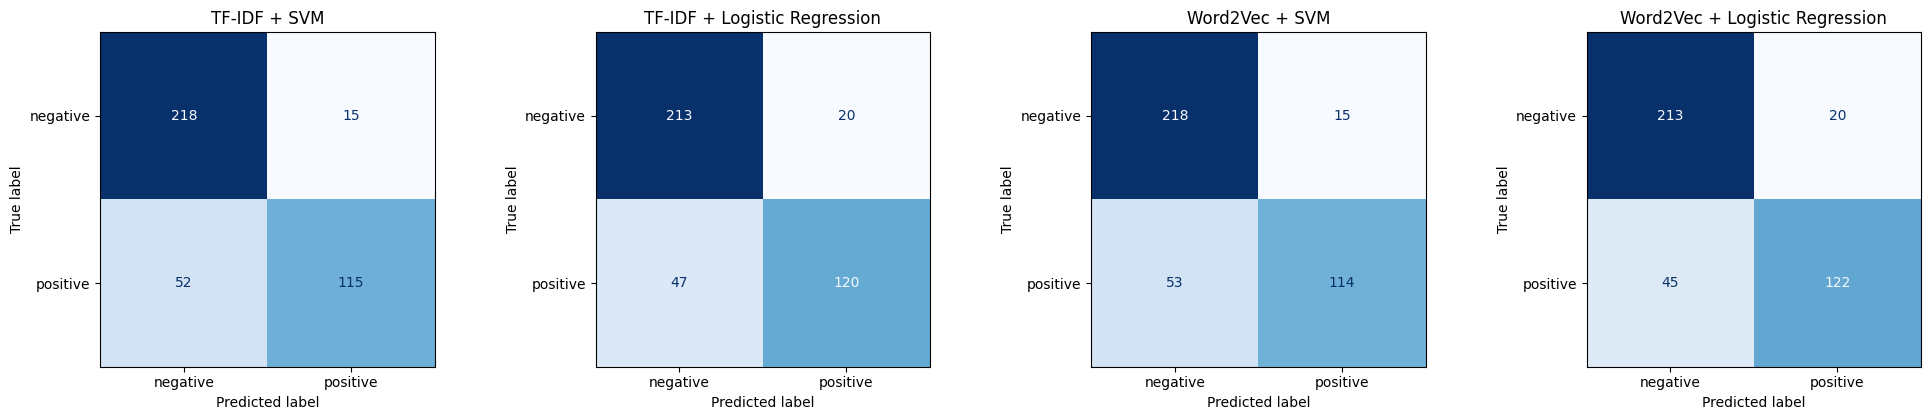

===== TF-IDF + SVM =====
              precision    recall  f1-score   support

    negative     0.8074    0.9356    0.8668       233
    positive     0.8846    0.6886    0.7744       167

    accuracy                         0.8325       400
   macro avg     0.8460    0.8121    0.8206       400
weighted avg     0.8396    0.8325    0.8282       400

===== TF-IDF + Logistic Regression =====
              precision    recall  f1-score   support

    negative     0.8192    0.9142    0.8641       233
    positive     0.8571    0.7186    0.7818       167

    accuracy                         0.8325       400
   macro avg     0.8382    0.8164    0.8229       400
weighted avg     0.8351    0.8325    0.8297       400

===== Word2Vec + SVM =====
              precision    recall  f1-score   support

    negative     0.8044    0.9356    0.8651       233
    positive     0.8837    0.6826    0.7703       167

    accuracy                         0.8300       400
   macro avg     0.8441    0.8091  

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
labels = sorted(y_test.unique())
for ax, ((_, rep, name), pred) in zip(axes, preds_original.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{rep} + {name}")
plt.tight_layout()
plt.show()

for (_, rep, name), pred in preds_original.items():
    print(f"===== {rep} + {name} =====")
    print(classification_report(y_test, pred, digits=4))

In [ ]:
rows = []
for (_, rep, name), pred in preds_original.items():
    pred = pd.Series(pred, index=test.index)
    row = {"Text Representation": rep, "Algorithm": name}
    for lang in LANG:
        mask = test["language"] == lang
        row[f"F1 ({lang})"] = round(f1_score(y_test[mask], pred[mask], average="macro"), 4)
    rows.append(row)
display(pd.DataFrame(rows))

,Text Representation,Algorithm,F1 (id),F1 (en)
0,TF-IDF,SVM,0.7763,0.8448
1,TF-IDF,Logistic Regression,0.7853,0.8450
2,Word2Vec,SVM,0.7982,0.8241
3,Word2Vec,Logistic Regression,0.8278,0.8201


# 7. If our data is imbalanced

### 7.1 How imbalanced is the data


label
negative    932
positive    665
Name: count, dtype: int64
Imbalance ratio (majority / minority): 1.4


label                 negative  positive
app         language                    
Crunchyroll en            56.2      43.8
            id            76.5      23.5
Netflix     en            25.1      74.9
            id            47.4      52.6
Prime Video en            67.5      32.5
            id            71.8      28.2

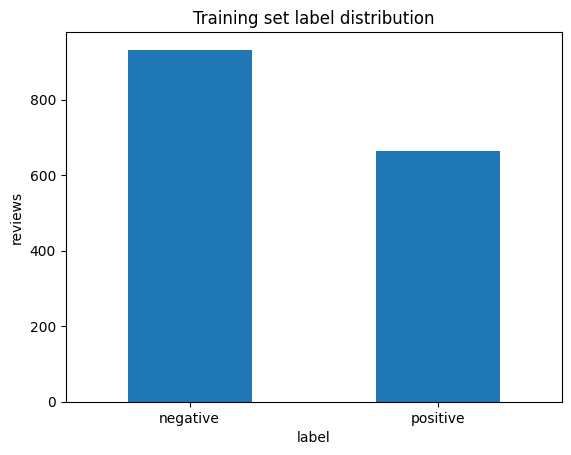

In [ ]:
counts = y_train.value_counts()
print(counts)
print("Imbalance ratio (majority / minority):", round(counts.max() / counts.min(), 2))
display(pd.crosstab([train["app"], train["language"]], train["label"], normalize="index").round(3) * 100)

counts.plot.bar(rot=0, title="Training set label distribution")
plt.ylabel("reviews")
plt.show()

Data sedikit imbalanced 

### 7.2 Treatments

In [ ]:
# Treatment 1: class weight
results_cw, preds_cw = train_all(X_sets, y_train, "class weight", class_weight="balanced")

# Treatment 2: random undersampling (training set only)
n_min = y_train.value_counts().min()
train_us = train.groupby("label").sample(n=n_min, random_state=RANDOM_STATE)
print("After undersampling:", train_us["label"].value_counts().to_dict())
X_sets_us = {"TF-IDF": (tfidf.transform(train_us["clean_text"]), X_test_tfidf),
             "Word2Vec": (np.vstack(train_us["w2v"]), X_test_w2v)}
results_us, preds_us = train_all(X_sets_us, train_us["label"], "undersampling")

After undersampling: {'negative': 665, 'positive': 665}


Ada dua cara untuk mengatasi imbalanced yaitu class weight, dan kedua ada random undersampling

### 7.3 Comparison before vs after

In [ ]:
all_results = pd.concat([results_original, results_cw, results_us], ignore_index=True)
recall_cols = [c for c in all_results.columns if c.startswith("Recall ")]
display(all_results[["Treatment", "Text Representation", "Algorithm", "Best Hyperparameters",
                     "Accuracy", "Precision", "Recall", "F1-score"] + recall_cols])
all_results.to_csv("results_summary.csv", index=False)

,Treatment,Text Representation,Algorithm,Best Hyperparameters,Accuracy,Precision,Recall,F1-score,Recall negative,Recall positive
0,original,TF-IDF,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'linear'}",0.8325,0.8460,0.8121,0.8206,0.9356,0.6886
1,original,TF-IDF,Logistic Regression,"{'C': 10, 'penalty': 'l2'}",0.8325,0.8382,0.8164,0.8229,0.9142,0.7186
2,original,Word2Vec,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.8300,0.8441,0.8091,0.8177,0.9356,0.6826
3,original,Word2Vec,Logistic Regression,"{'C': 0.1, 'penalty': 'l1'}",0.8375,0.8424,0.8224,0.8286,0.9142,0.7305
4,class weight,TF-IDF,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'linear'}",0.8300,0.8348,0.8142,0.8205,0.9099,0.7186
5,class weight,TF-IDF,Logistic Regression,"{'C': 1, 'penalty': 'l2'}",0.8575,0.8616,0.8446,0.8504,0.9227,0.7665
6,class weight,Word2Vec,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.8525,0.8551,0.8403,0.8455,0.9142,0.7665
7,class weight,Word2Vec,Logistic Regression,"{'C': 0.1, 'penalty': 'l1'}",0.8625,0.8593,0.8574,0.8583,0.8884,0.8263
8,undersampling,TF-IDF,SVM,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.8450,0.8487,0.8313,0.8371,0.9142,0.7485
9,undersampling,TF-IDF,Logistic Regression,"{'C': 1, 'penalty': 'l2'}",0.8500,0.8518,0.8382,0.8431,0.9099,0.7665


Setelah sampling matriks evaluasi pada beberapa model tertentu lebih bagus karena model tidak berat di satu kelas yang banyak

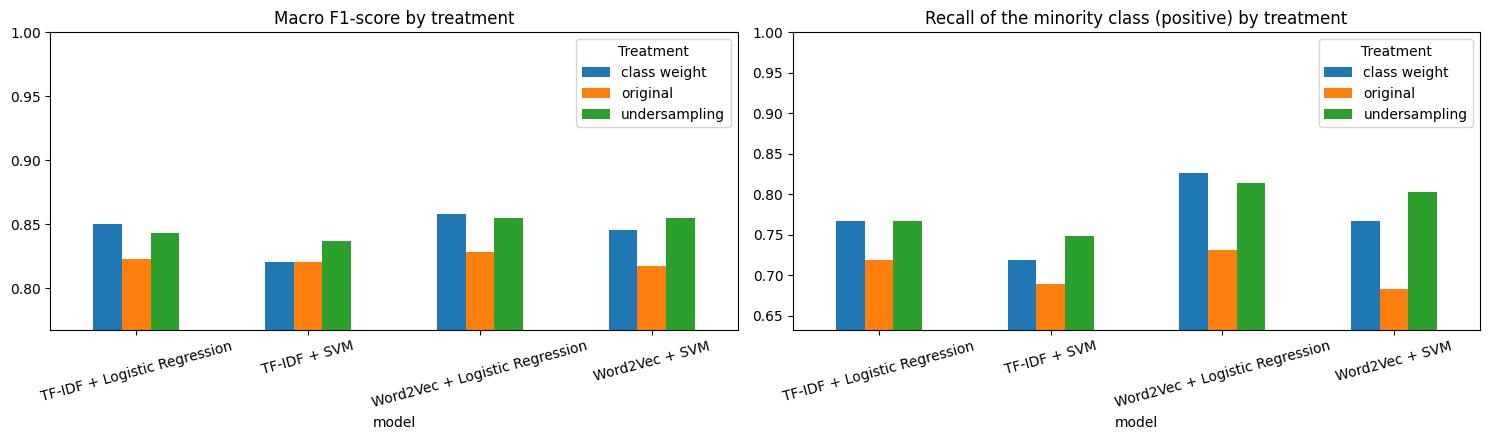

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
all_results["model"] = all_results["Text Representation"] + " + " + all_results["Algorithm"]
all_results.pivot(index="model", columns="Treatment", values="F1-score").plot.bar(ax=axes[0], rot=15)
axes[0].set_title("Macro F1-score by treatment")
axes[0].set_ylim(all_results["F1-score"].min() - 0.05, 1)

minority = y_train.value_counts().idxmin()
all_results.pivot(index="model", columns="Treatment", values=f"Recall {minority}").plot.bar(ax=axes[1], rot=15)
axes[1].set_title(f"Recall of the minority class ({minority}) by treatment")
axes[1].set_ylim(all_results[f"Recall {minority}"].min() - 0.05, 1)
plt.tight_layout()
plt.show()

# 8 Evaluate which app that recommended

In [ ]:
rows = []
all_preds = {**preds_original, **preds_cw, **preds_us}
for (treatment, rep, name), pred in all_preds.items():
    pred = pd.Series(pred, index=test.index)
    row = {"Treatment": treatment, "Model": f"{rep} + {name}"}
    for app in apps:
        row[app] = round(100 * (pred[test["app"] == app] == "positive").mean(), 1)
    rows.append(row)
true_row = {"Treatment": "actual labels", "Model": "-"}
for app in apps:
    true_row[app] = round(100 * (y_test[test["app"] == app] == "positive").mean(), 1)
display(pd.DataFrame(rows + [true_row]))

,Treatment,Model,Netflix,Prime Video,Crunchyroll
0,original,TF-IDF + SVM,47.3,24.4,28.6
1,original,TF-IDF + Logistic Regression,49.1,29.9,29.2
2,original,Word2Vec + SVM,46.4,27.6,26.1
3,original,Word2Vec + Logistic Regression,49.1,32.3,28.6
4,class weight,TF-IDF + SVM,49.1,29.1,30.4
5,class weight,TF-IDF + Logistic Regression,53.6,28.3,31.1
6,class weight,Word2Vec + SVM,51.8,30.7,31.7
7,class weight,Word2Vec + Logistic Regression,53.6,37.0,35.4
8,undersampling,TF-IDF + SVM,50.0,30.7,31.1
9,undersampling,TF-IDF + Logistic Regression,52.7,29.9,32.3


Untuk aplikasi yang rekomennya ada pada Netflix kedua Prime Video atau Crunchyroll